In [1]:
from ech_discovery.notebook import *
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as scipy_stats

# Load data

In [2]:
df = cv.load_data("timing_statistics_all")

/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/ech-penalty/lin_all_location-grouped_main_all.png


/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/ech-penalty/lin_all_location-grouped_followup_all.png


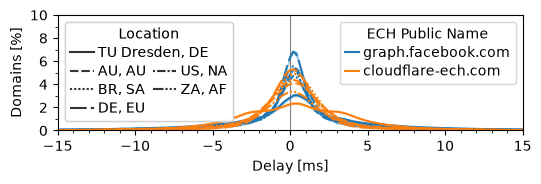

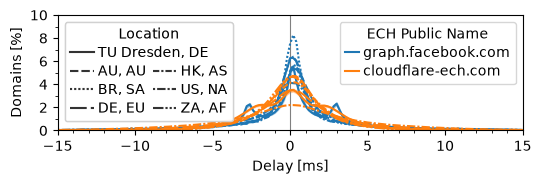

In [3]:
dash_map = {
    region_map["tud"]: "",  # solid
    region_map["australia-southeast1"]: (4, 1.5),  # medium dash
    region_map["southamerica-east1"]: (1, 1),  # dotted
    region_map["europe-west10"]: (8, 2),  # long dash
    region_map["asia-east2"]: (3, 1, 1, 1),  # dash-dot
    region_map["us-west2"]: (1, 1, 4, 1),  # dot-dash
    region_map["africa-south1"]: (5, 1, 1, 1, 1, 1),  # dash-dot-dot
}

pinned = region_map["tud"]
value_order = [pinned] + sorted((v for v in region_map.values() if v != pinned))

for period in ["main", "followup"]:
    Z = scipy_stats.norm.ppf(0.975)
    # Pre-calculate per group
    stats = (
        df.filter(RANGES[period].expr())
        .collect()
        .filter(
            pl.col(C.ech_public_name).is_in(config.MAIN_ECH_PUBLIC_NAMES),
            pl.col(C.hs_duration_diff) >= -15,
            pl.col(C.hs_duration_diff) <= 15,
            pl.col(C.role) == "ech",
        )
        .group_by([C.ech_public_name, C.role, C.location, C.hs_duration_diff])
        .agg(
            pl.col(C.len_percent).mean(),
            pl.col(C.len_percent).quantile(0.001).alias(C.percentile_min),
            pl.col(C.len_percent).quantile(0.99).alias(C.percentile_max),
            pl.col(C.len_percent).std().alias(C.std),
            pl.col(C.len_percent).count().alias(C.len),
        )
        .with_columns((Z * pl.col(C.std) / pl.col(C.len).sqrt()).alias(C.error))
        .with_columns(
            pl.col(C.location).replace_strict(region_map).cast(pl.Enum(value_order))
        )
        .sort(C.hs_duration_diff, C.location, descending=[False, False])
        .with_columns(pl.col(C.location).cast(pl.String))
    )
    fig, ax = vh.fig_ax()
    ax.vlines(0, 0, 10, "grey", linewidth=0.8)

    sns.lineplot(
        stats,
        x=C.hs_duration_diff,
        y=C.len_percent,
        hue=C.ech_public_name,
        style=C.location,
        dashes=dash_map,
        hue_order=[
            config.PUBLIC_NAME_META,
            config.PUBLIC_NAME_CLOUDFLARE,
        ],
    )
    palette = {line.get_label(): line.get_color() for line in ax.lines}

    for label, group in stats.group_by(C.ech_public_name, C.location):

        group = group.sort(C.hs_duration_diff)
        ax.fill_between(
            group[C.hs_duration_diff],
            group[C.len_percent] - group[C.error],
            group[C.len_percent] + group[C.error],
            alpha=0.3,
            color=palette[label[0]],
        )

    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

    from matplotlib.offsetbox import HPacker, VPacker

    legend1 = ax.legend(
        handles[1:3],
        labels[1:3],
        loc="upper right",
        title=Strings.ech_public_name,
        handlelength=1,
        handletextpad=0.3,
        borderpad=0.4,
        labelspacing=0.3,
        columnspacing=0.5,
    )
    ax.add_artist(legend1)

    legend2 = ax.legend(
        handles[4:],
        labels[4:],
        loc="upper left",
        title=Strings.location,
        handlelength=1.7,
        handletextpad=0.3,
        borderpad=0.4,
        labelspacing=0.3,
        ncol=1,
    )
    ax.add_artist(legend2)

    fs = legend2._fontsize
    rows = legend2._legend_handle_box.get_children()[0].get_children()
    first, rest = rows[0], rows[1:]
    half = -(-len(rest) // 2)

    cols = HPacker(
        children=[
            VPacker(children=rest[:half], align="left", pad=0, sep=fs * 0.3),
            VPacker(children=rest[half:], align="left", pad=0, sep=fs * 0.3),
        ],
        align="top",
        pad=0,
        sep=fs * 0.5,
    )
    new_box = VPacker(children=[first, cols], align="left", pad=0, sep=fs * 0.3)

    legend2._legend_handle_box = new_box
    legend2._legend_box._children[-1] = new_box
    legend2._legend_box.set_figure(fig)
    legend2._legend_box.stale = True
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(2))

    ax.set(ylim=(0, 10))
    ax.set(xlim=(-15, 15))

    ax.set(ylabel=Strings.latency)
    ax.set(xlabel=Strings.delay)
    role, location, measurement = "all", "location-grouped", "all"

    vh.save_plot(
        fig,
        f"lin_{role}_{location}_{period}_{str(measurement).replace(":", "_").replace(" ", "_")}",
        config.FIGURES_DIR / "ech-penalty",
    )